# Real estate: povertà del quartiere e valore delle case

*Metodi Matematici e Statistici per le Decisioni Economiche · A.A. 2026/27 · Lezione 2*

[![Apri in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vincnardelli/msd/blob/main/codice/2/lab_real_estate.ipynb)

Un'agenzia immobiliare vuole capire quanto il livello socioeconomico di un quartiere pesa sul valore delle case a Boston.
`boston.csv` descrive 506 quartieri: `medv` (valore mediano delle case, migliaia di \$), `lstat` (% di popolazione a basso reddito), `rm` (stanze medie), `age` (% di case costruite prima del 1940), `dis` (distanza dai centri di lavoro).

In [1]:
import polars as pl
from plotnine import *
import statsmodels.formula.api as smf

In [2]:
boston = pl.read_csv("https://www.vincnardelli.com/msd/dati/boston.csv")
boston.head()

crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,lstat,medv
f64,f64,f64,i64,f64,f64,f64,f64,i64,i64,f64,f64,f64
0.00632,18.0,2.31,0,0.538,6.575,65.2,4.09,1,296,15.3,4.98,24.0
0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,9.14,21.6
0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,4.03,34.7
0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,2.94,33.4
0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,5.33,36.2


### 1. Le due variabili, una alla volta

In [3]:
boston.select("lstat", "medv").describe()

statistic,lstat,medv
str,f64,f64
"""count""",506.0,506.0
"""null_count""",0.0,0.0
"""mean""",12.653063,22.532806
"""std""",7.141062,9.197104
"""min""",1.73,5.0
"""25%""",6.93,17.0
"""50%""",11.38,21.2
"""75%""",16.96,25.0
"""max""",37.97,50.0


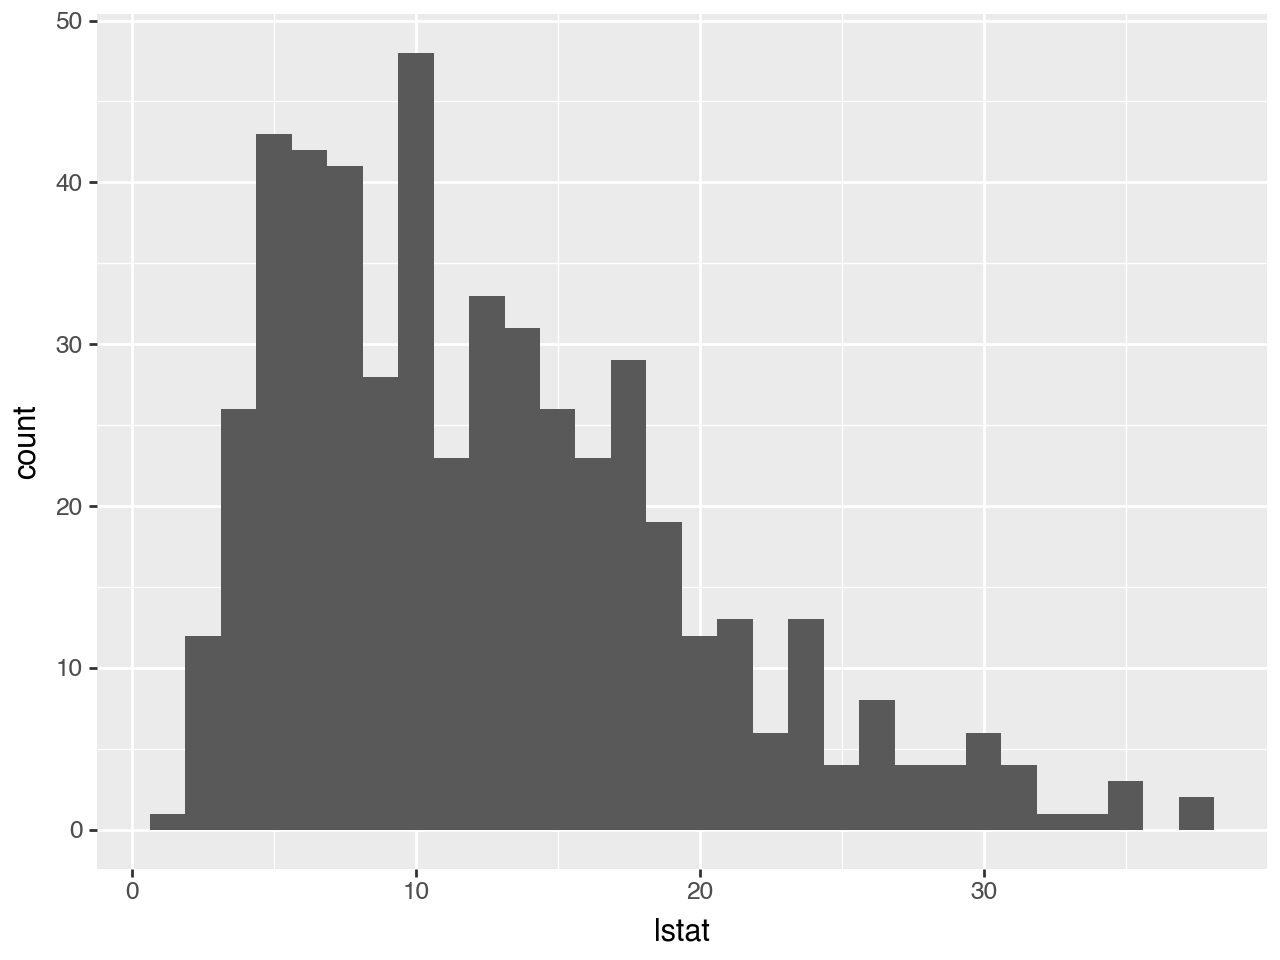

In [4]:
ggplot(boston, aes(x="lstat")) + geom_histogram(bins=30)

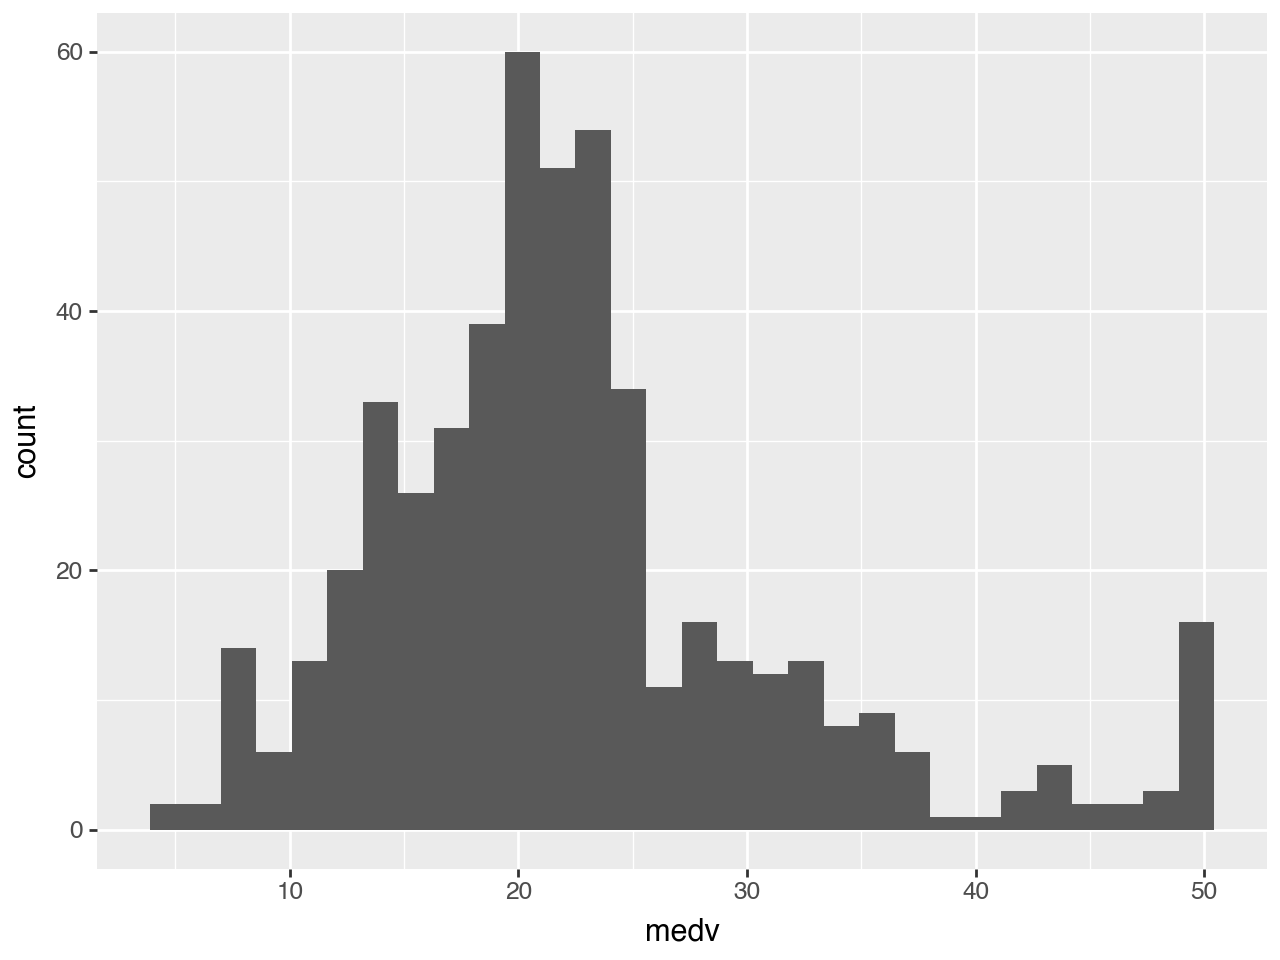

In [5]:
ggplot(boston, aes(x="medv")) + geom_histogram(bins=30)

`lstat` è asimmetrica a destra: molti quartieri sotto il 15%, pochi sopra il 30%. `medv` ha un picco a 50: i valori sono stati troncati a 50.000 \$.

### 2. La relazione tra povertà e valore

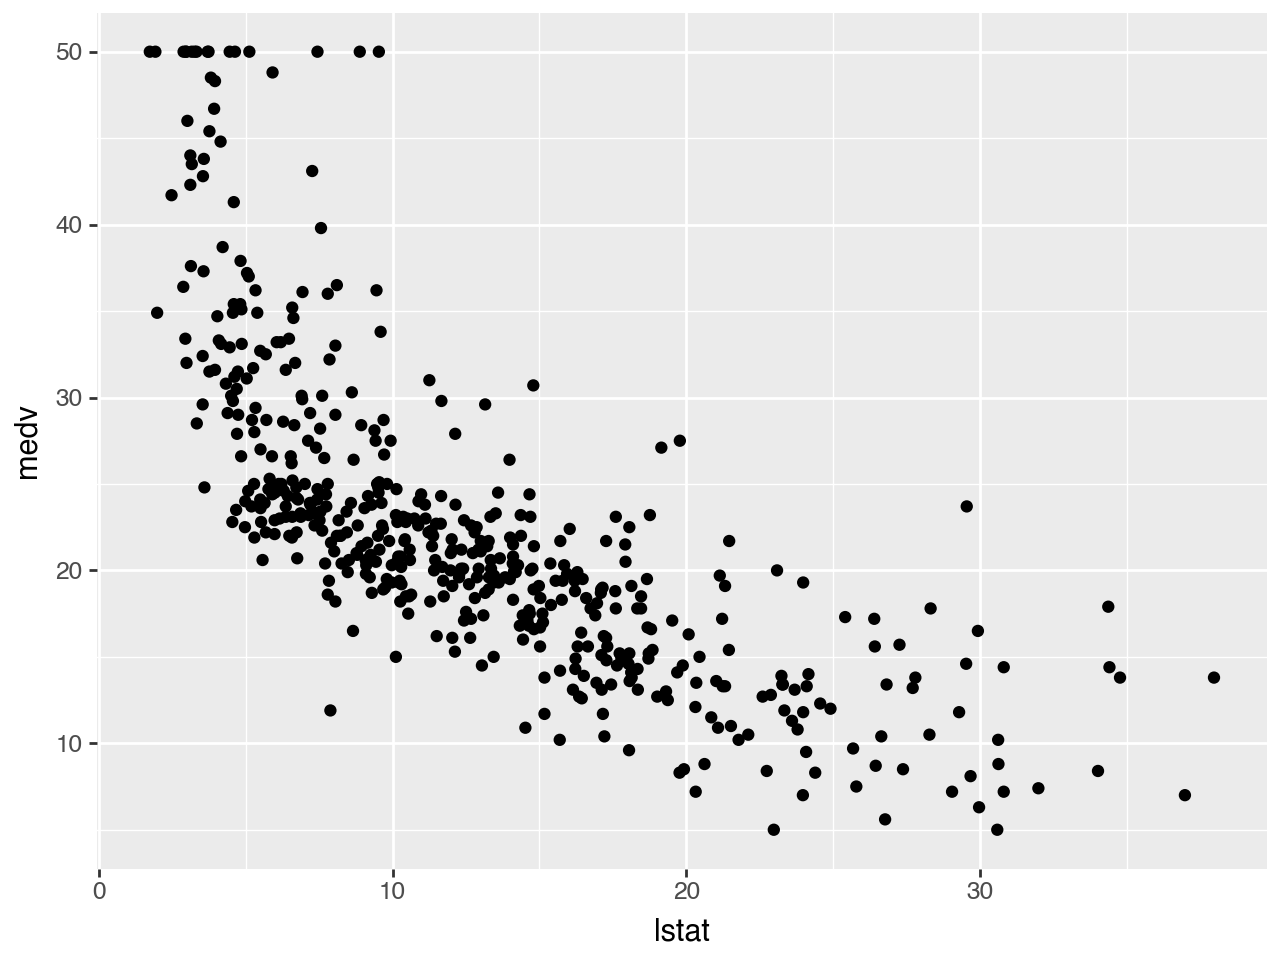

In [6]:
ggplot(boston, aes(x="lstat", y="medv")) + geom_point()

In [7]:
boston.select("lstat", "medv").corr()

lstat,medv
f64,f64
1.0,-0.737663
-0.737663,1.0


La relazione è negativa e forte, con correlazione −0,74: più povertà nel quartiere, case che valgono meno.

### 3. La retta `medv ~ lstat`

In [8]:
modello = smf.ols("medv ~ lstat", data=boston).fit()
modello.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   medv   R-squared:                       0.544
Model:                            OLS   Adj. R-squared:                  0.543
Method:                 Least Squares   F-statistic:                     601.6
Date:                Tue, 10 Nov 2026   Prob (F-statistic):           5.08e-88
Time:                        12:50:25   Log-Likelihood:                -1641.5
No. Observations:                 506   AIC:                             3287.
Df Residuals:                     504   BIC:                             3295.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     34.5538      0.563     61.415      0.000      33.448      35.659
lstat         -0.9500      0.039    -24.528      0.000      -1.026      -0.874
==============================================================================
Omnibus:                      137.043   Durbin-Watson:                   0.892
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              291.373
Skew:                           1.453   Prob(JB):                     5.36e-64
Kurtosis:                       5.319   Cond. No.                         29.7
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

L'intercetta, 34,55, è il valore atteso in un quartiere senza popolazione a basso reddito. La pendenza, −0,95, dice che ogni punto percentuale in più di `lstat` si associa a 950 \$ in meno di valore. L'$R^2$ è 0,544: `lstat` spiega il 54% della variabilità.

### 4. Previsioni per quartieri con il 5%, il 10% e il 15% di popolazione a basso reddito

In [9]:
modello.get_prediction({"lstat": [5, 10, 15]}).summary_frame(alpha=0.05)

,mean,mean_se,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
0,29.803594,0.405247,29.007412,30.599776,17.565675,42.041513
1,25.053347,0.294814,24.474132,25.632563,12.827626,37.279068
2,20.303101,0.290893,19.731588,20.874613,8.077742,32.528459


Le colonne `mean_ci` danno l'intervallo per la media dei quartieri, `obs_ci` quello, molto più largo, per un singolo quartiere.

### 5. È davvero una retta?

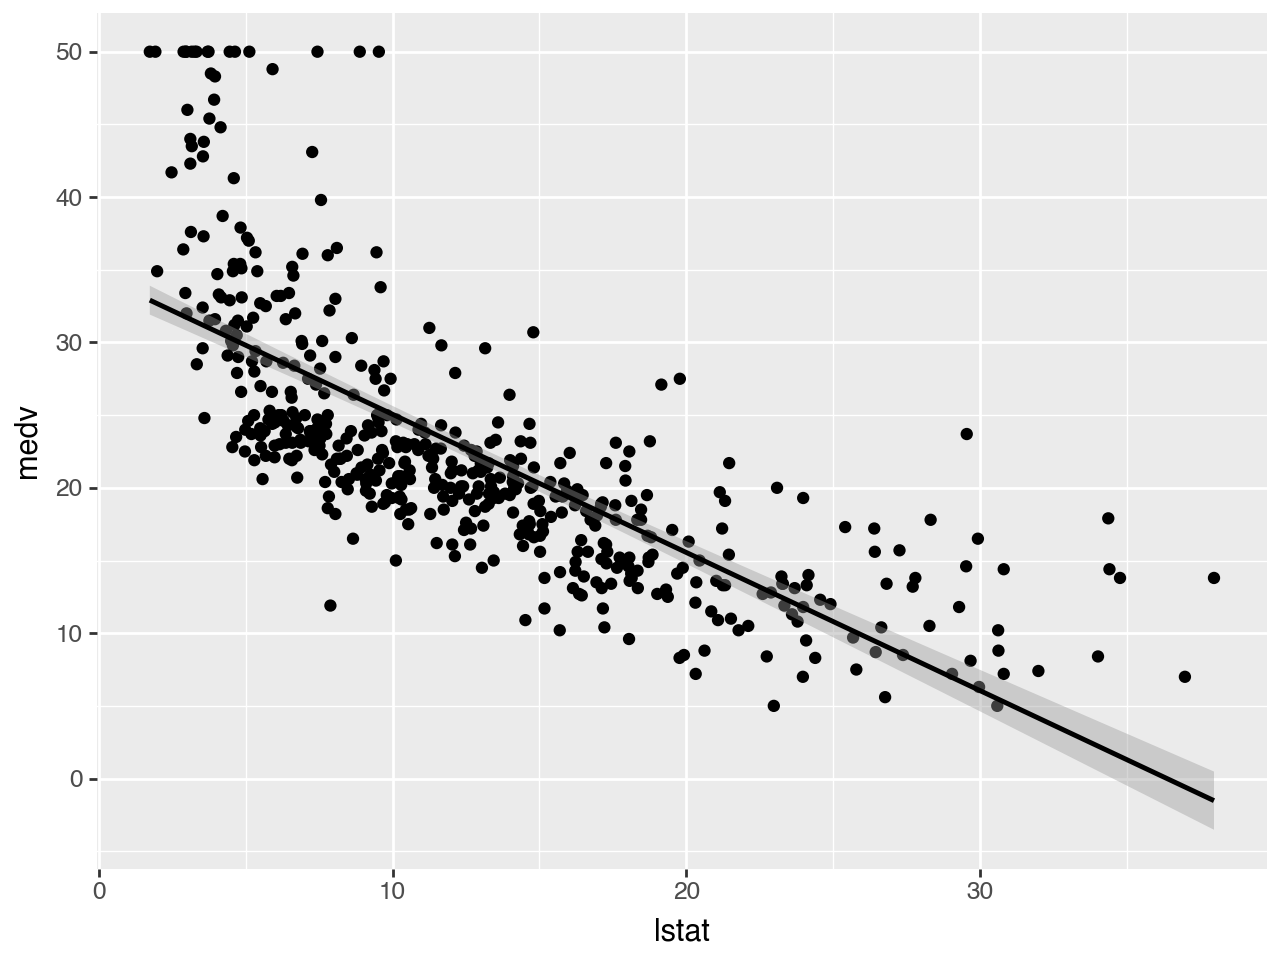

In [10]:
ggplot(boston, aes(x="lstat", y="medv")) + geom_point() + geom_smooth(method="lm")

I punti disegnano una curva: la retta sovrastima il valore nei quartieri a `lstat` intermedio e lo sottostima agli estremi. Una retta è un buon primo passo, non l'ultimo.

### 6. Aggiungere `rm`, `age` e `dis`

In [11]:
multiplo = smf.ols("medv ~ lstat + rm + age + dis", data=boston).fit()
multiplo.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   medv   R-squared:                       0.649
Model:                            OLS   Adj. R-squared:                  0.646
Method:                 Least Squares   F-statistic:                     231.6
Date:                Tue, 10 Nov 2026   Prob (F-statistic):          2.09e-112
Time:                        12:50:25   Log-Likelihood:                -1575.4
No. Observations:                 506   AIC:                             3161.
Df Residuals:                     501   BIC:                             3182.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      4.0799      3.437      1.187      0.236      -2.672      10.832
lstat         -0.6848      0.054    -12.721      0.000      -0.791      -0.579
rm             4.9904      0.449     11.126      0.000       4.109       5.872
age           -0.0255      0.014     -1.771      0.077      -0.054       0.003
dis           -0.6588      0.175     -3.767      0.000      -1.002      -0.315
==============================================================================
Omnibus:                      124.062   Durbin-Watson:                   0.869
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              355.890
Skew:                           1.171   Prob(JB):                     5.24e-78
Kurtosis:                       6.376   Cond. No.                     1.08e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.08e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

L'$R^2$ sale a 0,649. Il coefficiente di `lstat` passa da −0,95 a −0,68: una parte del suo effetto era dovuta al numero di stanze, che va insieme alla povertà del quartiere. `age` non è significativa a parità delle altre (p = 0,08).